### Быстрая проверка работоспособности

##### CUDA + cupy

In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
import cupy as cp
import numpy as np
import matplotlib.pyplot as plt
arr = cp.array([1, 2, 3])
arr2 = cp.array([1, 2, 3])
np.sqrt((arr - arr2)**3)

array([0., 0., 0.])

In [3]:
dev_cnt = cp.cuda.runtime.getDeviceCount()
print(f"GPUs available: {dev_cnt}")

GPUs available: 2


### Демо работы с разными солверами

##### Брутфорс

In [4]:
from qubo_lib.problems import TSP
from qubo_lib.solvers import QBF

# Задача коммивояжера, 5 случайных городов
tsp_problem = TSP.init_random_instance(n_cities = 5, seed = 42) 

# Создадим брутфорс-солвер, QBF это QUBO bruteforce
solver = QBF()

# Решаем задачу брутфорсом на CPU
solution = solver.solve(tsp_problem) 
print(solution)

Solution(
  N=25,
  best_E=-713.532,
  time_to_solve_ms=56.3,
  samples_cnt=1,
  solver_class='QBF',
  best_X='0010000010100000000101000'
)


In [5]:
# Возьмем задачу побольше, решим тем же солвером, брутфорсом, но уже на видеокарте
# Тут требуется время на прогрев - компиляцию cuda-ядер
tsp_36_bits = TSP.init_random_instance(n_cities = 6, seed = 42) 
solution = solver.solve(tsp_36_bits, device = 'cuda')
print(solution)

Solution(
  N=36,
  best_E=-882.774,
  time_to_solve_ms=1458.6,
  samples_cnt=1,
  solver_class='QBF',
  best_X='100000010000000010001000000001000100'
)


In [6]:
# Можем распараллелить на 2 видеокарты, 
# Parallel обеспечивает запуск на нескольких устройствах
from qubo_lib.solvers import Parallel

# QBF - солвер, экземпляр которого будет работать на каждом из устройств
solver = Parallel(base_solver=QBF, splits_cnt=2, devices=['cuda'] * 2)
solution = solver.solve(tsp_36_bits)
print(solution)

Solution(
  N=36,
  best_E=-882.774,
  time_to_solve_ms=1093.2,
  samples_cnt=1,
  solver_class='QBF',
  best_X='100000010000000010001000000001000100'
)


In [7]:
# Можем распараллелить в несколько потоков на CPU
from qubo_lib.solvers import Parallel
solver = Parallel(base_solver=QBF, splits_cnt=8, devices=['cpu'] * 8)
solution = solver.solve(tsp_36_bits)
print(solution)

Solution(
  N=36,
  best_E=-882.774,
  time_to_solve_ms=6191.8,
  samples_cnt=1,
  solver_class='QBF',
  best_X='100000010000000010001000000001000100'
)


##### Очень быстрый брутфорс на GPU, только для типа int16

In [ ]:
import numpy as np
from qubo_lib.solvers import QB_F1, Parallel
from qubo_lib.problems import RandomQUBO
# Еще один класс задач, случайная QUBO-матрица
problem = RandomQUBO.init_random_instance(N=44, seed=42, dtype=np.int16)
solver = QB_F1()
# Тут укажем на какой именно видеокарте запустить
solution_qbf1 = solver.solve(problem, device='cuda:1')
print(solution_qbf1)

In [ ]:
# Параллельно тоже запускается
solver = Parallel(base_solver=QB_F1, splits_cnt=2, devices=['cuda'] * 2)
solution = solver.solve(problem)
print(solution)

Solution(
  N=44,
  best_E=-6902.000,
  time_to_solve_ms=11650.9,
  samples_cnt=1,
  solver_class='QB_F1',
  best_X='10100001111001000111110111111001101111011011'
)


##### MSSA солвер - алгоритм Simulated Annealing на GPU

In [10]:
# Это другой класс солвера
from qubo_lib.solvers import MSSA
solver = MSSA()

# Возьмем побольше городов 
tsp_50 = TSP.init_random_instance(n_cities = 50, seed = 42) 

# Решать будет пару минут
solution = solver.solve(tsp_50) 
print(solution)

Solution(
  N=2500,
  best_E=-11062.576,
  time_to_solve_ms=94893.7,
  samples_cnt=200,
  solver_class='MSSA',
  best_X='000000000000000000000000010000000000000000000000000000000000000000000001000000000000000000000000000010000000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000001000000000000000000000000000000100000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000010000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000000000100000000010000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000010000000000000000000000000000000000000000000000100000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000

In [11]:
# Метод MSSA.solve принимает такие аргументы
# def solve(self, problem: ProblemABC, samples_cnt=200, epochs_cnt=10, iters_per_epoch=10 ** 6, T=25, rand_seed=42, **kwargs) -> Solution:
    # :param samples_cnt: Number of simultaneous running SA samples. Multistarts
    # :param epochs_cnt: Number of temperature epochs, aka temperature schedule size
    # :param iters_per_epoch: SA iterations per one schedule epoch
    # :param T: Temperature schedule. Can be scalar, or np.ndarray epochs_cnt size

T_sched = np.geomspace(25, 0.1, num=500)
solution_50 = solver.solve(tsp_50, samples_cnt = 50, epochs_cnt = 500, iters_per_epoch = 1001, T = T_sched)
print(solution_50)

Solution(
  N=2500,
  best_E=-11198.523,
  time_to_solve_ms=7407.2,
  samples_cnt=50,
  solver_class='MSSA',
  best_X='10000000000000000000000000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000000001000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000100000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000001000000000000000000000000000010000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000000000000000000000000000000000000001000000000010000000000000000000000000000000000000000000000000000000000000000000000000000000100000000000001000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000

In [12]:
# MSSA можно запустить параллельно на нескольких GPU. Деления задачи на подзадачи не происходит
from qubo_lib.solvers import Parallel, MSSA
solver = Parallel(base_solver=MSSA, splits_cnt=2, devices=['cuda']*2)

# Общее число семплов total_samples_cnt = 500 будет поделено на splits_cnt=2 частей
solution = solver.solve(tsp_50, total_samples_cnt = 500, epochs_cnt = 500, iters_per_epoch = 1001, T = T_sched)
print(solution)

Solution(
  N=2500,
  best_E=-11267.163,
  time_to_solve_ms=11025.5,
  samples_cnt=500,
  solver_class='MSSA',
  best_X='100000000000000000000000000000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000000000000000000000000100000000000000000000000000000001000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000010000010000000000000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000001000000000010000000000000000000000000000000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000000001000000000000010000000000000000000000000000000000000000000000000000100000000000000

### Демо разных классов задач

##### Задача коммивояжера - Traveling Salesman Problem - TSP

In [13]:
# Создадим случайную задачу TSP на 7 городов
tsp_problem = TSP.init_random_instance(n_cities = 7, seed = 42) 

In [14]:
# Просто посмотрим какие города выдал рандом
tsp_problem.cities

array([[77.39561 , 43.887844],
       [85.859795, 69.7368  ],
       [ 9.417735, 97.56223 ],
       [76.11397 , 78.60643 ],
       [12.811363, 45.038593],
       [37.079803, 92.6765  ],
       [64.38651 , 82.27616 ]], dtype=float32)

In [15]:
import numpy as np
import matplotlib.pyplot as plt
# И какая по ним была построена QUBO-матрица
Q = tsp_problem.build_Q_matrix()
print(np.round(Q[:10, :10]))
print(Q.shape)

[[-174.  348.  348.  348.  348.  348.  348.  348.   27.    0.]
 [   0. -174.  348.  348.  348.  348.  348.   27.  348.   27.]
 [   0.    0. -174.  348.  348.  348.  348.    0.   27.  348.]
 [   0.    0.    0. -174.  348.  348.  348.    0.    0.   27.]
 [   0.    0.    0.    0. -174.  348.  348.    0.    0.    0.]
 [   0.    0.    0.    0.    0. -174.  348.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0. -174.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0. -174.  348.  348.]
 [   0.    0.    0.    0.    0.    0.    0.    0. -174.  348.]
 [   0.    0.    0.    0.    0.    0.    0.    0.    0. -174.]]
(49, 49)


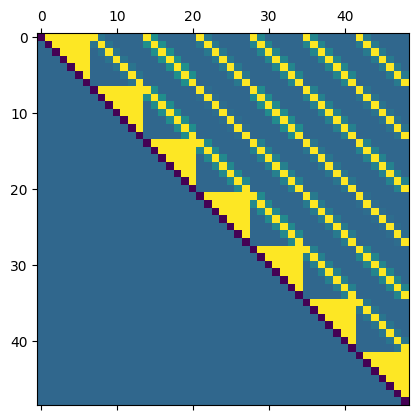

In [16]:
_ = plt.matshow(Q)

[[-134.  269.  269.  269.  269.  269.   14.    0.    0.    0.]
 [   0. -134.  269.  269.  269.   14.  269.   14.    0.    0.]
 [   0.    0. -134.  269.  269.    0.   14.  269.   14.    0.]
 [   0.    0.    0. -134.  269.    0.    0.   14.  269.   14.]
 [   0.    0.    0.    0. -134.    0.    0.    0.   14.  269.]
 [   0.    0.    0.    0.    0. -134.  269.  269.  269.  269.]
 [   0.    0.    0.    0.    0.    0. -134.  269.  269.  269.]
 [   0.    0.    0.    0.    0.    0.    0. -134.  269.  269.]
 [   0.    0.    0.    0.    0.    0.    0.    0. -134.  269.]
 [   0.    0.    0.    0.    0.    0.    0.    0.    0. -134.]]
(25, 25)


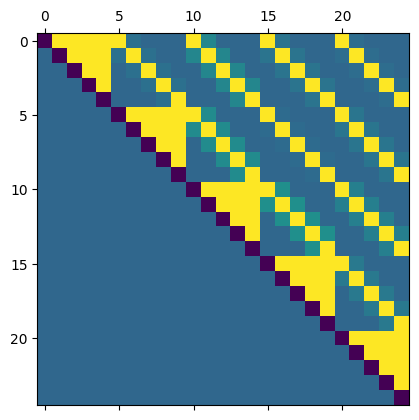

In [17]:
# Координаты городов можно задать явно
tsp5 = TSP.init_from_cities(np.array([(10, 40), (20, 30), (10, 90), (25, 25), (10, 50)]))
Q = tsp5.build_Q_matrix()
print(np.round(Q[:10, :10]))
print(Q.shape)
_ = plt.matshow(Q)

In [18]:
# Ранее мы решили задачу TSP на 50 городов с помощью MSSA, интересно насколько хорошее решение смогли найти?
# Найдем близкое приближение ground state 
tsp_50.calculate_ground()
print(f'Энергия MSSA: {solution_50.best_E:.2f}')
print(f'Граунд:       {tsp_50.ground_E:.2f}')

Энергия MSSA: -11198.52
Граунд:       -11942.17


##### MaxCut - задача максимального разреза графа
https://ru.wikipedia.org/wiki/%D0%9C%D0%B0%D0%BA%D1%81%D0%B8%D0%BC%D0%B0%D0%BB%D1%8C%D0%BD%D1%8B%D0%B9_%D1%80%D0%B0%D0%B7%D1%80%D0%B5%D0%B7_%D0%B3%D1%80%D0%B0%D1%84%D0%B0

MaxCut - очень популярный бенчмарк для различных методов дискретной оптимизации.   
Поддерживается база именованных графов, и лучших известных решений на них

In [19]:
from qubo_lib.problems import MaxCut
# Создаем граф G22 из стандартного набора maxcut-графов 
g22 = MaxCut('G22')
# Число неизвестных в QUBO-формулировке задачи MaxCut совпадает с числом вершин в графе 
print(f"Число вершин в графе: {g22.N}")
# Посмотрим лучшее известное решение для него, точнее его энергию в QUBO-формулировке
print(f"Лучшее известное решение: {g22.ground_E}")

Число вершин в графе: 2000
Лучшее известное решение: -13359


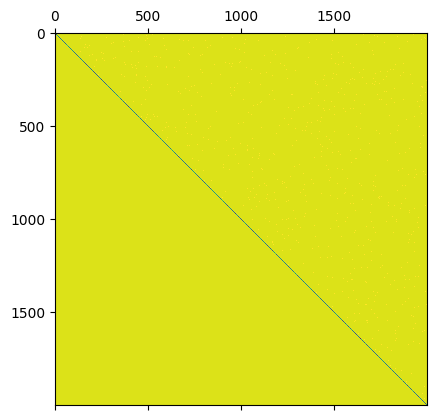

In [20]:
Q = g22.build_Q_matrix()
_ = plt.matshow(Q)

In [21]:
# Посмотрим как справится с этой задачей MSSA-солвер
##### Работает в контейнере на платформе cloud.ru
solver = MSSA()
T_sched = np.geomspace(2.5, 0.1, num=500)
solution = solver.solve(g22, samples_cnt = 10, epochs_cnt = 500, iters_per_epoch = 1001, T = T_sched)
print(f"Лучшее известное решение: {g22.ground_E}")
print(f"Решение найденное MSSA: {solution.best_E}")
print(f"Время решения, мсек: {solution.time_to_solve_ms:.1f}")

Лучшее известное решение: -13359
Решение найденное MSSA: -13358.0
Время решения, мсек: 3749.9


In [22]:
# Неплохо

##### Случайная QUBO-задача

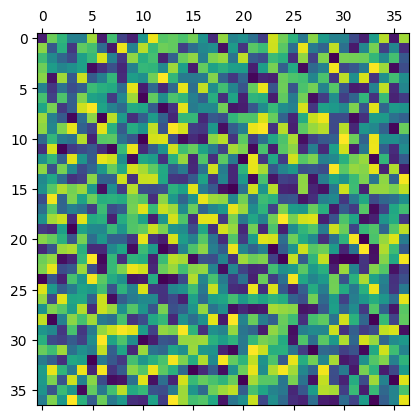

In [23]:
from qubo_lib.problems import RandomQUBO
rnd_problem = RandomQUBO.init_random_instance(seed = 42, N = 37)
Q = rnd_problem.build_Q_matrix()
_ = plt.matshow(Q)

In [24]:
# Решим брутфорсом на ЦПУ, будет долго, минуту
solver = QBF()
solution = solver.solve(rnd_problem)
print(solution)

Solution(
  N=37,
  best_E=-4251.922,
  time_to_solve_ms=52937.1,
  samples_cnt=1,
  solver_class='QBF',
  best_X='0101011110011001001010000111101110111'
)


In [25]:
# А теперь решим ее на видеокарте, должно быть быстрее
solver = QBF()
solution_1_gpu = solver.solve(rnd_problem, device = 'cuda')

# На двух видеокартах, будет еще быстрее
solver = Parallel(base_solver=QBF, splits_cnt=2, devices=['cuda'] * 2)
solution_2_gpu = solver.solve(rnd_problem)

print(f"Время решения на CPU, мсек: {solution.time_to_solve_ms}")
print(f"Время решения на одной GPU, мсек: {solution_1_gpu.time_to_solve_ms}")
print(f"Время решения на двух GPU, мсек: {solution_2_gpu.time_to_solve_ms}")

Время решения на CPU, мсек: 52937.106216326356
Время решения на одной GPU, мсек: 2576.6320890188217
Время решения на двух GPU, мсек: 1653.3334052562714


##### Кастомная QUBO-задача

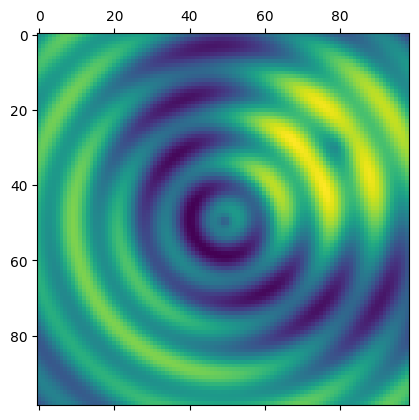

In [26]:
# Допустим нам нужно решить QUBO-задачу, которая не включена в библиотеку
# Построим кубо-матрицу для этой задачи
n = 99
matrix = np.zeros((n, n))
c1 = 0.5, 0.5
c2 = 0.3, 0.8
for i in range(n):
    for j in range(n):
        x, y = i/n, j/n
        d1 = np.sqrt((x - c1[0])**2 + (y - c1[1])**2)
        d2 = np.sqrt((x - c2[0])**2 + (y - c2[1])**2)
        wave1 = np.sin(d1*50) * np.exp(-d1)
        wave2 = np.sin(d2*10+0.3) * np.exp(-d2)
        matrix[i, j] = wave1 + 2*wave2

_ = plt.matshow(matrix)

In [27]:
# Теперь обернем эту матрицу в класс Just_Q и решим задачу на ней
from qubo_lib.problems import Just_Q
problem = Just_Q(matrix)
##### MSSA работает в контейнере на платформе cloud.ru
solver = MSSA()
solution = solver.solve(problem, iters_per_epoch=3*10**5)
print(solution)

Solution(
  N=99,
  best_E=-944.684,
  time_to_solve_ms=3991.2,
  samples_cnt=200,
  solver_class='MSSA',
  best_X='101011000000000001010000001111111110111111111111111111111111100000011100000000000000000000000001000'
)
